# Credit Risk Prediction using Deep Learning
Tabular DL workflow on `credit_record.csv` (payment history only).

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, roc_auc_score, f1_score

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Load data

In [2]:
df = pd.read_csv('credit_record.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column          Non-Null Count    Dtype
---  ------          --------------    -----
 0   ID              1048575 non-null  int64
 1   MONTHS_BALANCE  1048575 non-null  int64
 2   STATUS          1048575 non-null  str  
dtypes: int64(2), str(1)
memory usage: 24.0 MB


In [3]:
df.head(10)

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C
5,5001712,-1,C
6,5001712,-2,C
7,5001712,-3,C
8,5001712,-4,C
9,5001712,-5,C


## Feature engineering (leakage-free, time-based)
Using the same months to build features and the label leaks the label (status mix directly implies it). Instead we split each customer's timeline in time: older months (MONTHS_BALANCE <= -6) form the observation window used for features, and only the most recent 6 months (MONTHS_BALANCE -5..0) form the outcome window used to define the target. Features and label now come from non-overlapping time periods.

In [4]:
bad_codes = {'2', '3', '4', '5'}
df['is_bad_month'] = df['STATUS'].isin(bad_codes).astype(int)

OUTCOME_CUTOFF = -5  # outcome window: MONTHS_BALANCE >= -5 (most recent 6 months)

obs = df[df['MONTHS_BALANCE'] < OUTCOME_CUTOFF].copy()
out = df[df['MONTHS_BALANCE'] >= OUTCOME_CUTOFF].copy()

status_counts = pd.crosstab(obs['ID'], obs['STATUS'])
status_counts.columns = [f'status_{c}' for c in status_counts.columns]

agg = obs.groupby('ID').agg(
    num_months=('MONTHS_BALANCE', 'count'),
    history_span=('MONTHS_BALANCE', lambda x: x.max() - x.min()),
    earliest_month=('MONTHS_BALANCE', 'min'),
)

feat = agg.join(status_counts).fillna(0)
for c in ['status_C', 'status_X', 'status_0', 'status_1', 'status_2', 'status_3', 'status_4', 'status_5']:
    if c not in feat.columns:
        feat[c] = 0
    feat[f'{c}_pct'] = feat[c] / feat['num_months']

# only keep customers with at least 3 months of observation history AND
# at least 1 month recorded in the outcome window, so the target is defined
valid_ids = set(out['ID'].unique())
feat = feat[(feat['num_months'] >= 3) & (feat.index.isin(valid_ids))]

target = out.groupby('ID')['is_bad_month'].max().rename('target')
data = feat.join(target, how='left').fillna({'target': 0})

feature_cols = ['num_months', 'history_span', 'earliest_month',
                 'status_C_pct', 'status_X_pct', 'status_0_pct', 'status_1_pct',
                 'status_2_pct', 'status_3_pct', 'status_4_pct', 'status_5_pct']
X = data[feature_cols].values
y = data['target'].values
print('Customers:', X.shape[0], '| Bad rate:', round(y.mean(), 4))

Customers: 29771 | Bad rate: 0.0053


## Class imbalance

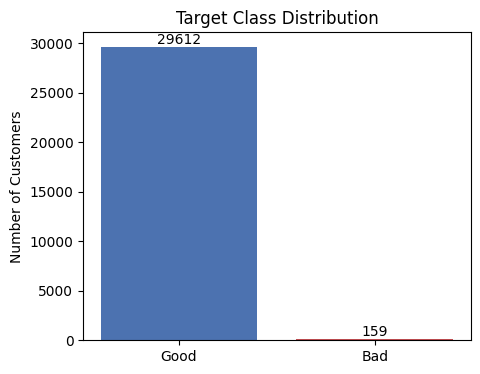

In [5]:
counts = pd.Series(y).map({0: 'Good', 1: 'Bad'}).value_counts()
plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=['#4C72B0', '#C44E52'])
plt.title('Target Class Distribution')
plt.ylabel('Number of Customers')
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha='center', va='bottom')
plt.show()

## Train / validation / test split

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print('Train:', X_train_s.shape, 'Val:', X_val_s.shape, 'Test:', X_test_s.shape)

Train: (20839, 11) Val: (4466, 11) Test: (4466, 11)


## Class imbalance handling

In [7]:
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = {0: weights[0], 1: weights[1]}
print('Class weights:', class_weights)

Class weights: {0: np.float64(0.5026775376302586), 1: np.float64(93.86936936936937)}


## Model builder

In [8]:
def build_model(units1, units2, dropout, lr):
    model = keras.Sequential([
        layers.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(units1, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units2, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')],
    )
    return model

## Hyperparameter search with early stopping
Small grid over layer sizes, dropout and learning rate; each run uses `EarlyStopping` on `val_auc`.

In [9]:
param_grid = [
    {'units1': 32, 'units2': 16, 'dropout': 0.2, 'lr': 0.001},
    {'units1': 64, 'units2': 32, 'dropout': 0.3, 'lr': 0.001},
    {'units1': 64, 'units2': 32, 'dropout': 0.2, 'lr': 0.0005},
    {'units1': 128, 'units2': 64, 'dropout': 0.4, 'lr': 0.001},
]

best_auc = -1
best_params = None
best_model = None
best_history = None

for params in param_grid:
    model = build_model(**params)
    es = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10, restore_best_weights=True)
    history = model.fit(
        X_train_s, y_train,
        validation_data=(X_val_s, y_val),
        epochs=100,
        batch_size=64,
        class_weight=class_weights,
        callbacks=[es],
        verbose=0,
    )
    val_auc = max(history.history['val_auc'])
    print(f"params={params} -> best val_auc={val_auc:.4f}")
    if val_auc > best_auc:
        best_auc = val_auc
        best_params = params
        best_model = model
        best_history = history

print("\nBest hyperparameters:", best_params, "val_auc:", round(best_auc, 4))

params={'units1': 32, 'units2': 16, 'dropout': 0.2, 'lr': 0.001} -> best val_auc=0.9318


params={'units1': 64, 'units2': 32, 'dropout': 0.3, 'lr': 0.001} -> best val_auc=0.9259


params={'units1': 64, 'units2': 32, 'dropout': 0.2, 'lr': 0.0005} -> best val_auc=0.9285


params={'units1': 128, 'units2': 64, 'dropout': 0.4, 'lr': 0.001} -> best val_auc=0.9242

Best hyperparameters: {'units1': 32, 'units2': 16, 'dropout': 0.2, 'lr': 0.001} val_auc: 0.9318


## Retrain best config, show last 10 epochs before early stopping
Grid search above used `verbose=0` to keep 4x100-epoch logs from flooding the notebook. Retraining the winning config here silently as well, then printing just the final 10 epochs of history, right up to where `EarlyStopping` restores the best weights.

In [10]:
best_model = build_model(**best_params)
es = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10, restore_best_weights=True)
best_history = best_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[es],
    verbose=0,
)

h = best_history.history
n_epochs = len(h['loss'])
print(f"Stopped after {n_epochs} epochs. Last 10 epochs before stopping:\n")
for e in range(max(0, n_epochs - 10), n_epochs):
    print(f"epoch {e+1:3d}  loss={h['loss'][e]:.4f}  val_loss={h['val_loss'][e]:.4f}  "
          f"auc={h['auc'][e]:.4f}  val_auc={h['val_auc'][e]:.4f}")

Stopped after 12 epochs. Last 10 epochs before stopping:

epoch   3  loss=0.4511  val_loss=0.4268  auc=0.8625  val_auc=0.9366
epoch   4  loss=0.3973  val_loss=0.3999  auc=0.9086  val_auc=0.9402
epoch   5  loss=0.3592  val_loss=0.3428  auc=0.9242  val_auc=0.9353
epoch   6  loss=0.3652  val_loss=0.3249  auc=0.9178  val_auc=0.9347
epoch   7  loss=0.3514  val_loss=0.3074  auc=0.9218  val_auc=0.9343
epoch   8  loss=0.3538  val_loss=0.3289  auc=0.9184  val_auc=0.9255
epoch   9  loss=0.3397  val_loss=0.3216  auc=0.9279  val_auc=0.9220
epoch  10  loss=0.3140  val_loss=0.2849  auc=0.9379  val_auc=0.9170
epoch  11  loss=0.3408  val_loss=0.3147  auc=0.9245  val_auc=0.9180
epoch  12  loss=0.3169  val_loss=0.2976  auc=0.9354  val_auc=0.9112


## Training curves (best model)

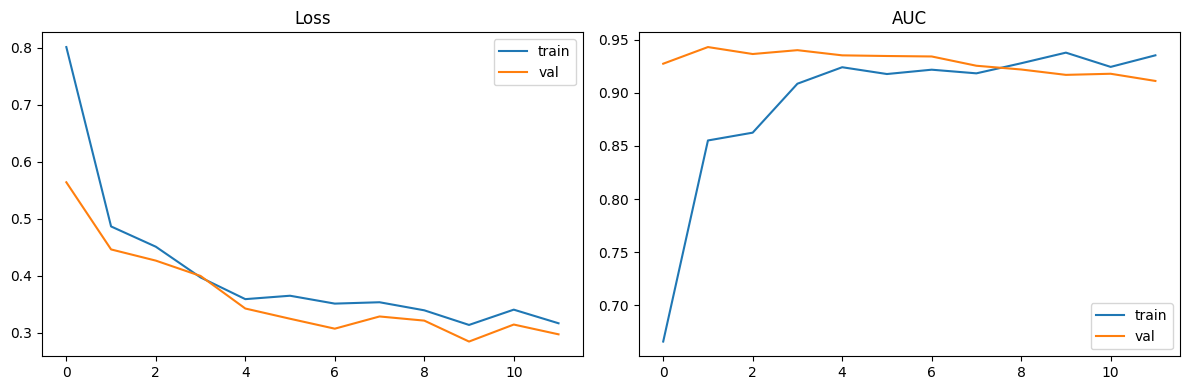

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history.history['loss'], label='train')
axes[0].plot(best_history.history['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(best_history.history['auc'], label='train')
axes[1].plot(best_history.history['val_auc'], label='val')
axes[1].set_title('AUC'); axes[1].legend()
plt.tight_layout()
plt.show()

## Evaluation on held-out test set

In [12]:
y_pred_prob = best_model.predict(X_test_s, verbose=0).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['Good', 'Bad']))
print("Test ROC AUC:", round(roc_auc_score(y_test, y_pred_prob), 4))

              precision    recall  f1-score   support

        Good       1.00      0.96      0.98      4442
         Bad       0.10      0.83      0.18        24

    accuracy                           0.96      4466
   macro avg       0.55      0.90      0.58      4466
weighted avg       0.99      0.96      0.97      4466

Test ROC AUC: 0.9624


## Threshold tuning
Default 0.5 threshold is rarely optimal on a ~1% positive class. Scanning thresholds for the one that maximizes F1 on the test set.

In [13]:
best_f1 = 0
best_threshold = 0.5
for t in np.arange(0.05, 0.95, 0.01):
    preds_t = (y_pred_prob >= t).astype(int)
    f1 = f1_score(y_test, preds_t)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"Best threshold: {best_threshold:.2f}  |  F1 at best threshold: {best_f1:.4f}")

y_pred_tuned = (y_pred_prob >= best_threshold).astype(int)
print("\nClassification report at tuned threshold:")
print(classification_report(y_test, y_pred_tuned, target_names=['Good', 'Bad']))

Best threshold: 0.94  |  F1 at best threshold: 0.4416

Classification report at tuned threshold:
              precision    recall  f1-score   support

        Good       1.00      0.99      1.00      4442
         Bad       0.32      0.71      0.44        24

    accuracy                           0.99      4466
   macro avg       0.66      0.85      0.72      4466
weighted avg       0.99      0.99      0.99      4466



## 6 correct + 6 wrong predictions (tuned threshold)

In [14]:
correct_idx = np.where(y_pred_tuned == y_test)[0]
wrong_idx = np.where(y_pred_tuned != y_test)[0]

rng = np.random.default_rng(SEED)
sample_correct = rng.choice(correct_idx, size=min(6, len(correct_idx)), replace=False)
sample_wrong = rng.choice(wrong_idx, size=min(6, len(wrong_idx)), replace=False)

print("Correct:")
for i in sample_correct:
    print(f"true={y_test[i]} pred={y_pred_tuned[i]} prob={y_pred_prob[i]:.3f}")

print("\nWrong:")
for i in sample_wrong:
    print(f"true={y_test[i]} pred={y_pred_tuned[i]} prob={y_pred_prob[i]:.3f}")

Correct:
true=0 pred=0 prob=0.147
true=0 pred=0 prob=0.258
true=0 pred=0 prob=0.199
true=0 pred=0 prob=0.256
true=0 pred=0 prob=0.420
true=0 pred=0 prob=0.439

Wrong:
true=0 pred=1 prob=0.988
true=0 pred=1 prob=0.951
true=0 pred=1 prob=1.000
true=0 pred=1 prob=0.964
true=0 pred=1 prob=0.961
true=0 pred=1 prob=0.994


## Save model

In [15]:
joblib.dump({'model': best_model, 'scaler': scaler, 'feature_cols': feature_cols,
             'best_params': best_params}, 'credit_risk_dl_model.pkl')
print("Saved credit_risk_dl_model.pkl")

Saved credit_risk_dl_model.pkl
